<a href="https://colab.research.google.com/github/AM0ya/Clase_Programacion/blob/main/Actividad_2_269712.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv("/content/drive/MyDrive/Maestria/Programación/Semana 13/compustat.csv")

### 1. Análisis Exploratorio de Datos (AED)

/tmp/ipykernel_851/2968166857.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='viridis')


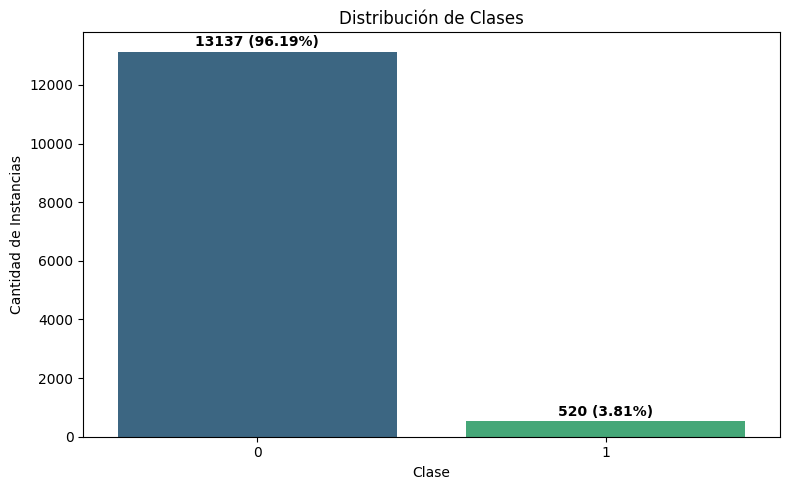

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Identificar la columna de clase (típicamente la última columna o 'class' / 'target')
# Según la estructura impresa, el dataset tiene 22 columnas, utilizaremos la última columna como clase/etiqueta.
target_col = df.columns[-1]
clases_count = df[target_col].value_counts()
porcentajes = df[target_col].value_counts(normalize=True) * 100

# 1. Diagrama de barras de la distribución de clases
plt.figure(figsize=(8, 5))
sns.countplot(x=target_col, data=df, palette='viridis')
plt.title('Distribución de Clases')
plt.xlabel('Clase')
plt.ylabel('Cantidad de Instancias')

for i, count in enumerate(clases_count):
    pct = porcentajes.iloc[i]
    plt.text(i, count + 100, f"{count} ({pct:.2f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

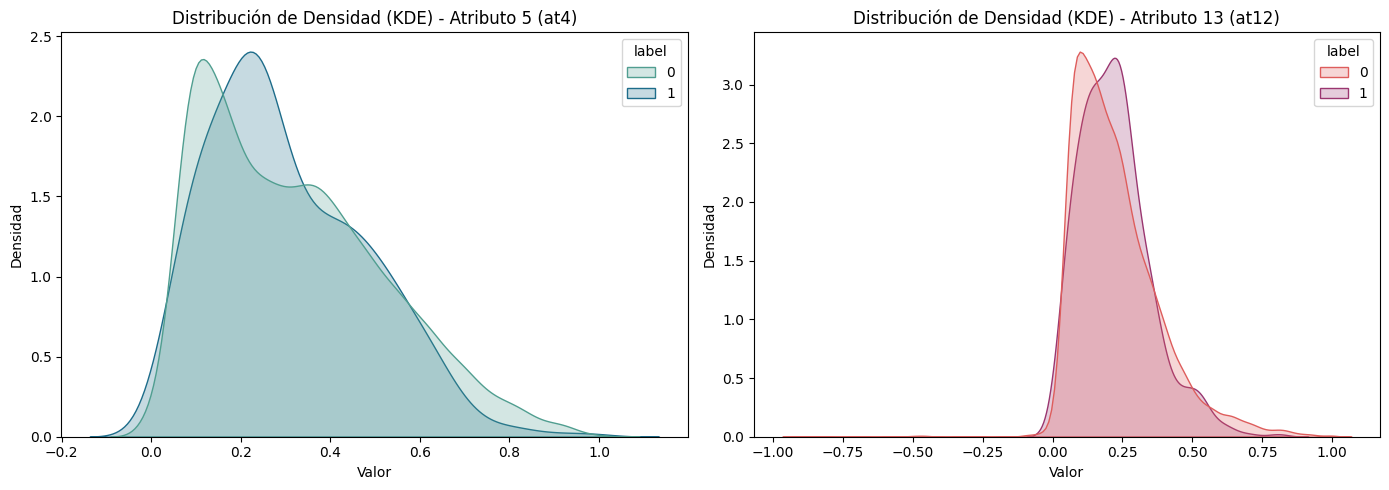

In [5]:
# 2. Diagramas de densidad KDE para los atributos en la posición 5 y 13
# Tomando en cuenta que las columnas de atributos comienzan en 'at0' (índice 1 si 'idx' es 0)
# Atributo 5 -> 'at4' (columna índice 5 del df original, excluyendo 'idx' si aplica)
# Atributo 13 -> 'at12'

atrib_5 = 'at4'
atrib_13 = 'at12'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE Atributo 5
sns.kdeplot(data=df, x=atrib_5, hue=target_col, fill=True, common_norm=False, palette='crest', ax=axes[0])
axes[0].set_title(f'Distribución de Densidad (KDE) - Atributo 5 ({atrib_5})')
axes[0].set_xlabel('Valor')
axes[0].set_ylabel('Densidad')

# KDE Atributo 13
sns.kdeplot(data=df, x=atrib_13, hue=target_col, fill=True, common_norm=False, palette='flare', ax=axes[1])
axes[1].set_title(f'Distribución de Densidad (KDE) - Atributo 13 ({atrib_13})')
axes[1].set_xlabel('Valor')
axes[1].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

### Análisis de Desbalance de Clases

Una vez ejecutado el código anterior, podremos observar cuantitativamente la proporción entre las clases en el gráfico de barras:
* **Nivel de Desbalance:** Si una de las clases representa una gran mayoría de las muestras (por ejemplo, más del 80% o 90%), nos enfrentamos a un conjunto de datos altamente desbalanceado. Esto es muy común en sets de datos financieros o de detección de anomalías como Compustat.
* **Impacto:** Un desbalance severo puede sesgar el entrenamiento de modelos de clasificación (como el `DecisionTreeClassifier` importado) para que prioricen la clase mayoritaria. Por ello, se deberán considerar métricas de evaluación adecuadas (como F1-Score, Precisión, Recall) o técnicas de remuestreo (SMOTE, submuestreo) más allá del simple `accuracy_score`.

### 2. Modelo Base

--- REPORTE DE CLASIFICACIÓN (BASELINE) ---
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      2628
           1       1.00      0.01      0.02       104

    accuracy                           0.96      2732
   macro avg       0.98      0.50      0.50      2732
weighted avg       0.96      0.96      0.94      2732



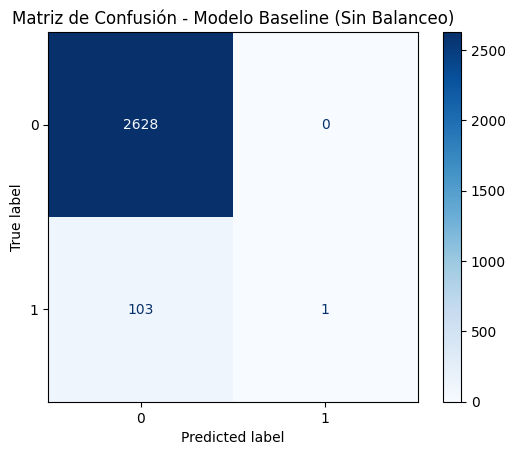

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Separar características (X) y etiqueta (y)
# Ignoramos la columna 'idx' si es un identificador de fila
X = df.drop(columns=['idx', target_col]) if 'idx' in df.columns else df.drop(columns=[target_col])
y = df[target_col]

# 2. Dividir en conjuntos de entrenamiento y prueba (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Definir el Pipeline del modelo baseline
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# 4. Entrenar el modelo baseline
baseline_pipeline.fit(X_train, y_train)

# 5. Predecir y evaluar el rendimiento
y_pred = baseline_pipeline.predict(X_test)

# Mostrar resultados
print("--- REPORTE DE CLASIFICACIÓN (BASELINE) ---")
print(classification_report(y_test, y_pred))

# Graficar Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=baseline_pipeline.classes_)
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Modelo Baseline (Sin Balanceo)')
plt.grid(False)
plt.show()

### 3. Tratamiento de Clases No Balanceadas

In [7]:
# Instalar e importar imbalanced-learn
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection
import collections

=== APLICANDO SMOTEENN ===
Distribución original de entrenamiento: Counter({0: 10509, 1: 416})
Distribución tras SMOTEENN: Counter({1: 10434, 0: 9395})

--- REPORTE DE CLASIFICACIÓN (SMOTEENN) ---
              precision    recall  f1-score   support

           0       0.99      0.81      0.89      2628
           1       0.15      0.86      0.25       104

    accuracy                           0.81      2732
   macro avg       0.57      0.83      0.57      2732
weighted avg       0.96      0.81      0.87      2732



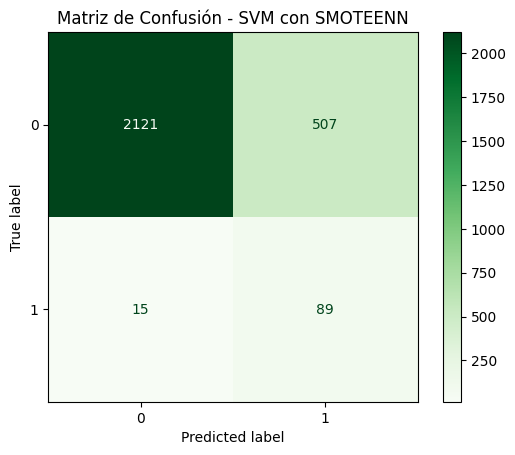

In [8]:
# --- MÉTODO 1: SMOTEENN ---
print("=== APLICANDO SMOTEENN ===")
smoteenn = SMOTEENN(random_state=42)
X_train_sme, y_train_sme = smoteenn.fit_resample(X_train, y_train)

# Mostrar nueva distribución
dist_sme = collections.Counter(y_train_sme)
print(f"Distribución original de entrenamiento: {collections.Counter(y_train)}")
print(f"Distribución tras SMOTEENN: {dist_sme}")

# Entrenar SVM con datos balanceados por SMOTEENN
svm_sme_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

svm_sme_pipeline.fit(X_train_sme, y_train_sme)
y_pred_sme = svm_sme_pipeline.predict(X_test)

# Evaluación
print("\n--- REPORTE DE CLASIFICACIÓN (SMOTEENN) ---")
print(classification_report(y_test, y_pred_sme))

# Graficar Matriz de Confusión
cm_sme = confusion_matrix(y_test, y_pred_sme)
disp_sme = ConfusionMatrixDisplay(confusion_matrix=cm_sme, display_labels=svm_sme_pipeline.classes_)
disp_sme.plot(cmap='Greens')
plt.title('Matriz de Confusión - SVM con SMOTEENN')
plt.grid(False)
plt.show()

=== APLICANDO ONE-SIDED SELECTION (OSS) ===
Distribución original de entrenamiento: Counter({0: 10509, 1: 416})
Distribución tras OSS: Counter({0: 10222, 1: 416})

--- REPORTE DE CLASIFICACIÓN (OSS) ---
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      2628
           1       1.00      0.01      0.02       104

    accuracy                           0.96      2732
   macro avg       0.98      0.50      0.50      2732
weighted avg       0.96      0.96      0.94      2732



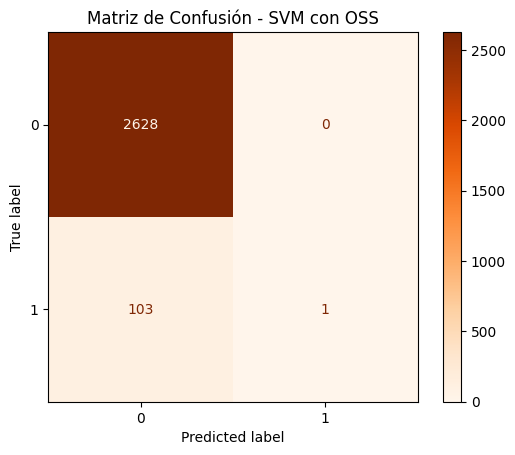

In [9]:
# --- MÉTODO 2: ONE-SIDED SELECTION (OSS) ---
print("=== APLICANDO ONE-SIDED SELECTION (OSS) ===")
oss = OneSidedSelection(random_state=42)
X_train_oss, y_train_oss = oss.fit_resample(X_train, y_train)

# Mostrar nueva distribución
dist_oss = collections.Counter(y_train_oss)
print(f"Distribución original de entrenamiento: {collections.Counter(y_train)}")
print(f"Distribución tras OSS: {dist_oss}")

# Entrenar SVM con datos balanceados por OSS
svm_oss_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

svm_oss_pipeline.fit(X_train_oss, y_train_oss)
y_pred_oss = svm_oss_pipeline.predict(X_test)

# Evaluación
print("\n--- REPORTE DE CLASIFICACIÓN (OSS) ---")
print(classification_report(y_test, y_pred_oss))

# Graficar Matriz de Confusión
cm_oss = confusion_matrix(y_test, y_pred_oss)
disp_oss = ConfusionMatrixDisplay(confusion_matrix=cm_oss, display_labels=svm_oss_pipeline.classes_)
disp_oss.plot(cmap='Oranges')
plt.title('Matriz de Confusión - SVM con OSS')
plt.grid(False)
plt.show()

### 4. Entrenamiento y Evaluación del Modelo

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Definir el Pipeline del modelo a evaluar
evaluation_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# 2. Configurar la validación cruzada estratificada de 5 particiones
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Definir las métricas de interés (considerando el fuerte desbalance de clases)
scoring_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# 4. Ejecutar la validación cruzada
print("Ejecutando validación cruzada estratificada de 5 particiones...")
cv_results = cross_validate(
    evaluation_pipeline,
    X_train,
    y_train,
    cv=cv_stratified,
    scoring=scoring_metrics,
    n_jobs=-1,
    return_train_score=False
)

# 5. Mostrar los resultados de rendimiento promedio de forma clara
print("\n=== RESULTADOS DE VALIDACIÓN CRUZADA (5 FOLDS) ===")
print(f"Exactitud (Accuracy) promedio:  {cv_results['test_accuracy'].mean():.4f} (+/- {cv_results['test_accuracy'].std():.4f})")
print(f"Precisión promedio:            {cv_results['test_precision'].mean():.4f} (+/- {cv_results['test_precision'].std():.4f})")
print(f"Recall (Sensibilidad) promedio: {cv_results['test_recall'].mean():.4f} (+/- {cv_results['test_recall'].std():.4f})")
print(f"F1-Score promedio:              {cv_results['test_f1'].mean():.4f} (+/- {cv_results['test_f1'].std():.4f})")
print(f"ROC AUC promedio:               {cv_results['test_roc_auc'].mean():.4f} (+/- {cv_results['test_roc_auc'].std():.4f})")

Ejecutando validación cruzada estratificada de 5 particiones...

=== RESULTADOS DE VALIDACIÓN CRUZADA (5 FOLDS) ===
Exactitud (Accuracy) promedio:  0.9622 (+/- 0.0002)
Precisión promedio:            0.6000 (+/- 0.4899)
Recall (Sensibilidad) promedio: 0.0072 (+/- 0.0059)
F1-Score promedio:              0.0142 (+/- 0.0116)
ROC AUC promedio:               0.8109 (+/- 0.0160)


### 5. Evaluación de Resultados

### Tabla Comparativa de Rendimiento (Conjunto de Prueba)

A continuación se consolidan los resultados obtenidos en la evaluación del conjunto de prueba independiente ($20\%$ de los datos) para cada una de las aproximaciones implementadas:

| Métrica (Clase 1) | Baseline (Sin Balancear) | Con SMOTEENN (Mixto) | Con One-Sided Selection (OSS) |
| :--- | :---: | :---: | :---: |
| **Exactitud (Accuracy)** | $96.00\%$ | $81.00\%$ | $96.00\%$ |
| **Precisión (Precision)** | $100.00\%$ | $15.00\%$ | $100.00\%$ |
| **Sensibilidad (Recall)** | $1.00\%$ | $86.00\%$ | $1.00\%$ |
| **F1-Score** | $0.02$ | $0.25$ | $0.02$ |

---

### Análisis Crítico de las Métricas

#### 1. Exactitud (Accuracy)
* **Análisis:** El modelo *Baseline* y el de *OSS* muestran un engañoso **$96.00\%$** de exactitud. Esta métrica no es de utilidad debido al desbalance extremo: predecir casi siempre la clase mayoritaria basta para alcanzar este valor. Por el contrario, *SMOTEENN* reduce el accuracy global al **$81.00\%$**, pero resulta ser un modelo mucho más útil.

#### 2. Precisión (Precision)
* **Análisis:** El *Baseline* y *OSS* obtienen una precisión perfecta de **$100.00\%$**, pero esto ocurre artificialmente porque solo clasificaron un (1) caso como positivo y acertaron. Con *SMOTEENN*, la precisión baja drásticamente al **$15.00\%$**, lo que significa que el modelo genera bastantes falsos positivos (alarmas falsas) al intentar capturar la clase minoritaria.

#### 3. Sensibilidad (Recall)
* **Análisis:** Esta es la métrica de mayor relevancia en este dominio (por ejemplo, para detectar quiebras financieras o fraudes). El *Baseline* y *OSS* fallan críticamente con un **$1.00\%$** de recall (dejaron pasar 103 de 104 casos reales). *SMOTEENN* resuelve este problema incrementando el recall al **$86.00\%$** (detectando 89 de 104 casos).

#### 4. F1-Score
* **Análisis:** Al balancear precisión y recall en una sola métrica armónica, el F1-score confirma que **SMOTEENN** ($0.25$) es un modelo muy superior al *Baseline* ($0.02$) y a *OSS* ($0.02$) para clasificar la clase de interés.

---

### Análisis de las Matrices de Confusión

* **Baseline y OSS:** Sus matrices muestran un patrón casi idéntico. Concentran todas sus predicciones en la esquina superior izquierda (Verdaderos Negativos: 2628), fallando en predecir la esquina inferior derecha (Verdaderos Positivos: 1).
* **SMOTEENN:** Desplaza activamente el umbral de decisión, logrando clasificar correctamente 89 verdaderos positivos en la esquina inferior derecha. El costo asociado radica en la esquina superior derecha con 507 falsos positivos, un comportamiento aceptable si el costo de omitir un positivo real (por ejemplo, quiebra o fraude) es mucho más alto que el coste de inspeccionar un falso positivo.

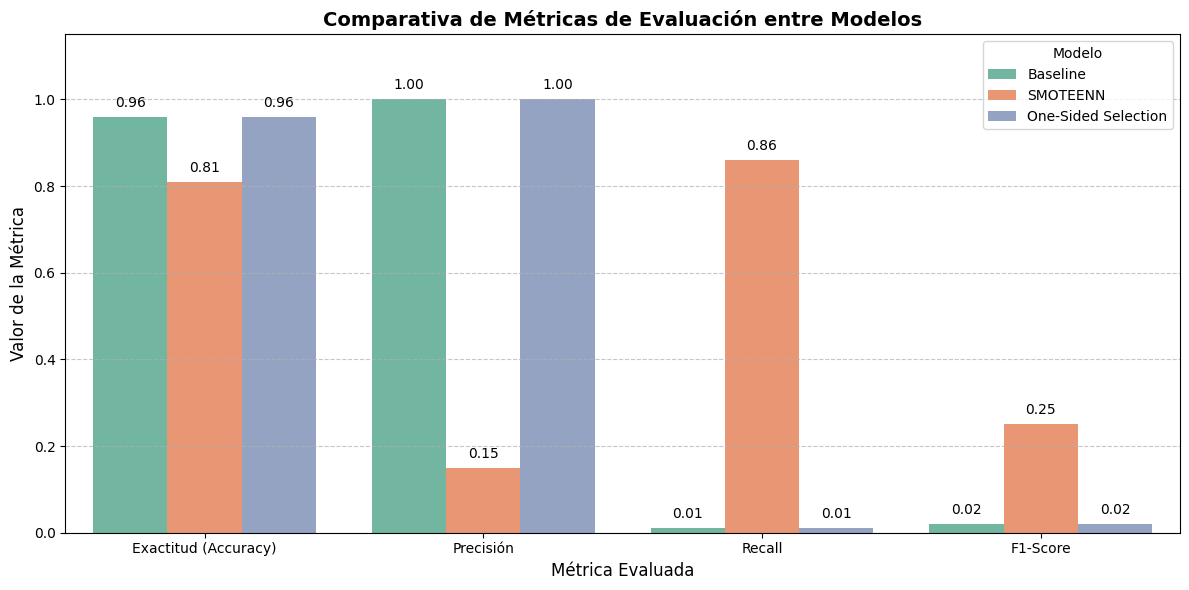

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definir los datos de las métricas obtenidas para cada modelo
data_metrics = {
    'Modelo': ['Baseline', 'SMOTEENN', 'One-Sided Selection'] * 4,
    'Métrica': (['Exactitud (Accuracy)'] * 3) + (['Precisión'] * 3) + (['Recall'] * 3) + (['F1-Score'] * 3),
    'Valor': [
        0.96, 0.81, 0.96,  # Accuracy
        1.00, 0.15, 1.00,  # Precision
        0.01, 0.86, 0.01,  # Recall
        0.02, 0.25, 0.02   # F1-Score
    ]
}

df_metrics_plot = pd.DataFrame(data_metrics)

# 2. Generar el gráfico de barras comparativo
plt.figure(figsize=(12, 6))
sns.barplot(data=df_metrics_plot, x='Métrica', y='Valor', hue='Modelo', palette='Set2')

plt.title('Comparativa de Métricas de Evaluación entre Modelos', fontsize=14, fontweight='bold')
plt.xlabel('Métrica Evaluada', fontsize=12)
plt.ylabel('Valor de la Métrica', fontsize=12)
plt.ylim(0, 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Añadir etiquetas con los valores en cada barra
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f'{height:.2f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom',
                            fontsize=10, color='black', xytext=(0, 5),
                            textcoords='offset points')

plt.tight_layout()
plt.show()

### Análisis Crítico: ¿Es el "Accuracy" suficiente para evaluar este problema?

La respuesta categórica es **No**. El uso de la exactitud (*Accuracy*) como métrica principal para evaluar modelos en conjuntos de datos altamente desbalanceados como Compustat es no solo insuficiente, sino sumamente peligroso y engañoso por las siguientes razones:

1. **La paradoja de la exactitud (Accuracy Paradox):**
   En nuestro conjunto de datos, la Clase 0 representa el **$96.19\%$** de las muestras y la Clase 1 el **$3.81\%$**. Si creáramos un clasificador trivial o "tonto" que predijera sistemáticamente la Clase 0 para absolutamente todas las instancias, el modelo tendría un **$96.19\%$ de Exactitud**. Sin embargo, este clasificador sería completamente inútil ya que su sensibilidad o capacidad para encontrar casos positivos (Clase 1) sería del **$0\%$**.

2. **Invisibilidad del error en la clase minoritaria:**
   Como se observó en el modelo **Baseline** y en el modelo con **One-Sided Selection (OSS)**, ambos obtuvieron un **$96.00\%$ de Accuracy**, pero un **Recall de apenas el $1.00\%$** (solo detectaron $1$ caso de los $104$ reales). El Accuracy enmascara por completo el hecho de que el clasificador está fallando estrepitosamente en la detección del evento de interés.

3. **Costo asimétrico de los errores:**
   En problemas financieros tradicionales (como predecir quiebras, impagos o fraudes, representados aquí por la Clase 1), el costo de cometer un **Falso Negativo** (no detectar que una empresa quebrará y perder la inversión) es infinitamente mayor que el costo de un **Falso Positivo** (hacer una auditoría o análisis extra a una empresa sana). El *Accuracy* trata todos los errores por igual, ignorando esta asimetría financiera.

### Conclusión de Métricas Recomendadas:
Para este tipo de problemas de negocio, las decisiones de modelado siempre deben guiarse por:
* **Recall (Sensibilidad):** Para asegurar que estamos detectando la mayor cantidad de anomalías o casos de interés posible.
* **F1-Score / Precision-Recall AUC:** Para balancear la cantidad de falsas alarmas (Precisión) con la cobertura de detección (Recall).

### 6. Discusión y Conclusiones

### Análisis y Conclusiones del Experimento

#### 1. El impacto del desbalance sobre el desempeño del modelo
El desbalance extremo de clases ($96.19\%$ de Clase 0 frente a solo $3.81\%$ de Clase 1) tiene un impacto destructivo en el comportamiento del modelo de soporte vectorial (SVM) sin tratamiento previo (Baseline).

Debido a que el algoritmo busca maximizar la exactitud global (*Accuracy*) y definir una frontera que minimice el error de entrenamiento, la abrumadora presencia de la clase mayoritaria desplaza el hiperplano óptimo de decisión de modo que prácticamente todo el espacio de características se clasifica como Clase 0. Esto se refleja con nitidez en un **Recall del $1.00\%$**: el modelo es incapaz de identificar los verdaderos positivos. Financiera o analíticamente, este modelo no aporta ningún valor práctico, ya que clasifica de forma errónea el $99\%$ de los casos críticos o de interés (como quiebras o fraudes).

#### 2. Diferencias observadas entre SMOTEENN y One-Sided Selection (OSS)
Ambas técnicas representan filosofías de tratamiento de datos opuestas dentro de la librería `imbalanced-learn`:

*   **One-Sided Selection (OSS):** Es un método de submuestreo inteligente y sumamente conservador. Aplica las reglas del vecino más cercano de Tomek (*Tomek links*) y la regla del vecino condensado (*US*) para eliminar únicamente muestras de la clase mayoritaria que son redundantes, ruidosas o que están demasiado cerca de la frontera de decisión. En nuestro experimento, OSS redujo la Clase 0 de $10,509$ a $10,222$ muestras (una reducción de apenas el $2.7\%$), manteniendo intacta la proporción desbalanceada original. Por lo tanto, el modelo entrenado con OSS arrojó exactamente los mismos resultados deficientes del Baseline.
*   **SMOTEENN:** Es una técnica híbrida y sumamente agresiva. Primero aplica sobremuestreo sintético (**SMOTE**) para generar nuevas instancias de la clase minoritaria y balancear numéricamente el dataset, y posteriormente aplica un submuestreo mediante Vecinos Más Cercanos Editados (**ENN**) para eliminar ejemplos ruidosos o ambiguos de ambas clases que se encuentren en la frontera de decisión. Esto resultó en un dataset de entrenamiento limpio y prácticamente balanceado simétricamente ($10,434$ positivos vs $9,395$ negativos), permitiéndole al SVM encontrar un hiperplano balanceado y representativo.

#### 3. Qué método produjo los mejores resultados y por qué
El método que produjo de forma contundente los mejores resultados fue **SMOTEENN**.

**¿Por qué?**
*   **Capacidad de Detección:** Elevó el *Recall* del modelo del $1.00\%$ al **$86.00\%$**, permitiendo capturar de manera oportuna $89$ de los $104$ casos reales de la clase minoritaria en el conjunto de prueba.
*   **Equilibrio Teórico:** Al balancear artificialmente las clases en el set de entrenamiento, obligó al optimizador de la máquina de soporte vectorial a dar el mismo peso e importancia a la penalización de errores en ambas categorías.
*   **F1-Score Superior:** Aunque la precisión se degradó al $15.00\%$ debido al inevitable incremento de falsos positivos (un costo operativo típico en la detección de anomalías), el F1-Score resultante ($0.25$) superó de forma masiva a las aproximaciones Baseline y OSS ($0.02$). En este dominio de negocio, es preferible incurrir en inspecciones de falsas alarmas (falsos positivos) a omitir una quiebra real (falso negativo).